# 01 Bereinigung – Beschleunigung und Magnetfeld für die Fensterbildung

**Ziel des Projekts:** herausfinden, welcher Versuch zu welchem Maschinenzustand gehört (**Basis, Zustand 1, Zustand 2**). Dafür werden die Signale später in Fenster zerlegt und daraus Features berechnet (`02_Fenster_Features.ipynb`).

Dieses Notebook sorgt dafür, dass dort nur **gültige Daten** ankommen. Es verwendet nur die beiden Sensoren, die wir für den Test nutzen: **Beschleunigung** (`Accelerometer.csv`, mit Schwerkraft) und **Magnetfeld** (`Magnetometer.csv`).

1. Duplikate prüfen
2. Zeitachse und Fehlwerte prüfen
3. Aufnahmepausen: Messungen in Segmente teilen
4. Ungültige Abschnitte markieren (Handhabung, verschobenes Handy)
5. Bereinigte Daten speichern (`clean/`) und Abdeckung darstellen

Die doppelten Ordner wurden bereits **aus den Rohdaten gelöscht** (byte-identische Kopien, siehe Datenregeln unten). Abschnitt 1 prüft, dass keine mehr vorhanden sind.

In [1]:
import hashlib, re, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings('ignore')   # hide library deprecation warnings so the outputs stay readable

# Path to the raw data – the only line you need to change on another computer
DATA_ROOT = Path('/Users/majasmereczynska/Documents/Industrial AI/IPR_Daten_neu/data/Hybridachse')
CLEAN = Path('clean'); CLEAN.mkdir(exist_ok=True)       # cleaned data for the next notebook
FIG = Path('figures'); FIG.mkdir(exist_ok=True)

# Cleaning parameters (justified in the data rules at the end)
JERK = 15.0        # m/s² – |linear acceleration| above this = phone was touched (normal start/stop: max 11.7)
MARGIN = 1.0       # s – removed before and after a jerk
SHIFT = 10.0       # µT – |B| at the end differs from the start by more = phone lies somewhere else afterwards
MIN_SEG = 1.0      # s – shorter segments (between two pauses) are dropped

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'font.size': 9, 'legend.frameon': False})
pd.set_option('display.width', 250, 'display.max_columns', 30, 'display.max_rows', 60, 'display.max_colwidth', 60)

## 1 · Messungen einlesen und Duplikate prüfen

Jede Messung bekommt eine einheitliche ID `Vxx_FP_nn` / `Vxx_IP_nn`. Die Nummer kommt aus dem Ordnernamen (`FP_02`, `Fairphone02`, `iPhone_03`, …). Ordner ohne Nummer (`Schiene`, `Fairphone`, `Alle Sensoren …`) werden pro Gerät nach Startzeit nummeriert. Der Original-Ordner bleibt in der Tabelle stehen.

In [2]:
def xyz(df):
    # Sensor tables: first column = time, then x, y, z (column names differ between Android and iOS)
    df = df.iloc[:, :4].copy()
    df.columns = ['t', 'x', 'y', 'z']
    return df

rec = []
for time_file in sorted(DATA_ROOT.glob('*/**/meta/time.csv')):
    folder = time_file.parent.parent
    device = pd.read_csv(folder / 'meta/device.csv').set_index('property')['value']
    events = pd.read_csv(time_file)
    rec.append({'Versuch': re.match(r'Versuch(\d+)', folder.relative_to(DATA_ROOT).parts[0]).group(1),
                'Gerät': 'FP' if device['deviceModel'] == 'FP4' else 'IP',
                'Ordner': str(folder.relative_to(DATA_ROOT)), 'folder': folder,
                'Start': events['system time'].iloc[0], 'events': events,
                'md5': hashlib.md5((folder / 'Accelerometer.csv').read_bytes()).hexdigest()})
rec = pd.DataFrame(rec).sort_values(['Versuch', 'Gerät', 'Start']).reset_index(drop=True)

# Uniform ID: number from the folder name if there is one, otherwise the order of the start times
def number(row, k):
    m = re.search(r'(?:FP|IP|Fairphone|iPhone)_?(\d+)$', Path(row['Ordner']).name)
    return int(m.group(1)) if m else k + 1
rec['k'] = rec.groupby(['Versuch', 'Gerät']).cumcount()
rec['record_id'] = [f"V{r['Versuch']}_{r['Gerät']}_{number(r, r['k']):02d}" for _, r in rec.iterrows()]
rec = rec.sort_values('record_id').reset_index(drop=True)

print(len(rec), 'Messungen ·', rec['record_id'].nunique(), 'eindeutige IDs ·',
      rec['md5'].duplicated().sum(), 'Duplikate (identische Accelerometer.csv)')
rec[['record_id', 'Ordner']]

33 Messungen · 33 eindeutige IDs · 0 Duplikate (identische Accelerometer.csv)


,record_id,Ordner
0,V01_FP_01,Versuch01/Schiene
1,V02_FP_01,Versuch02/Fairphone
2,V02_IP_01,Versuch02/Alle Sensoren iPhone Achsenpos1 2024-12-09 11-...
3,V03_FP_01,Versuch03_Fairphone/Fairphone01
4,V03_FP_02,Versuch03_Fairphone/Fairphone02
5,V03_FP_03,Versuch03_Fairphone/Fairphone03
6,V03_IP_01,Versuch03_iPhone/Alle Sensoren 2024-12-09 11-50-01
7,V03_IP_02,Versuch03_iPhone/Alle Sensoren 2024-12-09 11-52-34
8,V03_IP_03,Versuch03_iPhone/Alle Sensoren 2024-12-09 11-56-01
9,V04_FP_01,Versuch04/Versuch04_Fairphone_01


## 2 · Zeitachse und Fehlwerte

Pro Messung und Sensor: Anzahl Werte, Abtastrate, Fehlwerte (NaN), Zeitstempel rückwärts oder doppelt.

In [3]:
SENS = {'acc': 'Accelerometer.csv', 'mag': 'Magnetometer.csv'}
raw, quality = {}, []
for _, r in rec.iterrows():
    for s, fname in SENS.items():
        df = xyz(pd.read_csv(r['folder'] / fname))
        raw[r['record_id'], s] = df
        dt = np.diff(df['t'].values)
        quality.append({'record_id': r['record_id'], 'Sensor': s, 'Werte': len(df),
                        'Abtastrate (Hz)': round(1 / np.median(dt)), 'NaN': int(df.isna().sum().sum()),
                        'rückwärts': int((dt < 0).sum()), 'doppelt': int((dt == 0).sum()),
                        'größter Abstand (s)': round(dt.max(), 3)})
quality = pd.DataFrame(quality)
print('Summe NaN:', quality['NaN'].sum(), '· rückwärts:', quality['rückwärts'].sum(), '· doppelt:', quality['doppelt'].sum())
quality.pivot(index='record_id', columns='Sensor', values=['Abtastrate (Hz)', 'NaN', 'größter Abstand (s)'])

Summe NaN: 0 · rückwärts: 0 · doppelt: 0


Abtastrate (Hz)         NaN      größter Abstand (s)       
Sensor                acc    mag  acc  mag                 acc    mag
record_id                                                            
V01_FP_01           427.0  100.0  0.0  0.0               0.026  0.160
V02_FP_01           427.0  100.0  0.0  0.0               0.002  0.010
V02_IP_01           100.0  100.0  0.0  0.0               0.010  0.010
V03_FP_01           427.0  100.0  0.0  0.0               0.002  0.010
V03_FP_02           427.0  100.0  0.0  0.0               0.002  0.010
V03_FP_03           427.0  100.0  0.0  0.0               0.038  0.149
V03_IP_01           100.0  100.0  0.0  0.0               0.010  0.010
V03_IP_02           100.0  100.0  0.0  0.0               0.010  0.010
V03_IP_03           100.0  100.0  0.0  0.0               0.010  0.010
V04_FP_01           427.0  100.0  0.0  0.0               0.002  0.010
V04_FP_02           427.0  100.0  0.0  0.0               0.002  0.010
V04_IP_01           100.0  100.0  0.0  0.0               0.010  0.010
V04_IP_02           100.0  100.0  0.0  0.0               0.010  0.010
V04_IP_03           100.0  100.0  0.0  0.0               0.010  0.010
V05_FP_01           427.0  100.0  0.0  0.0               0.002  0.010
V05_FP_02           427.0  100.0  0.0  0.0               0.002  0.010
V05_FP_03           427.0  100.0  0.0  0.0               0.035  0.204
V05_IP_01           100.0  100.0  0.0  0.0               0.010  0.010
V05_IP_02           100.0  100.0  0.0  0.0               0.010  0.010
V05_IP_03           100.0  100.0  0.0  0.0               0.010  0.010
V06_FP_01           427.0  100.0  0.0  0.0               0.002  0.010
V06_FP_02           427.0  100.0  0.0  0.0               0.002  0.010
V06_FP_03           427.0  100.0  0.0  0.0               0.002  0.010
V07_FP_01           427.0  100.0  0.0  0.0               0.002  0.010
V08_FP_01           427.0  100.0  0.0  0.0               0.002  0.010
V08_IP_01           100.0  100.0  0.0  0.0               0.010  0.010
V09_FP_01           427.0  100.0  0.0  0.0               0.002  0.010
V09_FP_02           427.0  100.0  0.0  0.0               0.002  0.010
V09_FP_03           427.0  100.0  0.0  0.0               0.002  0.010
V10_FP_01           427.0  100.0  0.0  0.0               0.002  0.010
V10_FP_02           427.0  100.0  0.0  0.0               0.002  0.010
V10_FP_03           427.0  100.0  0.0  0.0               0.002  0.010
V10_IP_03           100.0  100.0  0.0  0.0               0.010  0.010

## 3 · Aufnahmepausen → Segmente

**Wichtig:** Während einer Pause hält phyphox die Uhr an. Die Zeitstempel laufen danach **ohne Lücke** weiter, obwohl real Sekunden vergangen sind und das Handy dazwischen bewegt worden sein kann. Pausen erkennt man deshalb nicht an einer Lücke in den Daten, sondern nur an den START-Ereignissen in `meta/time.csv`. Jede Messung wird an diesen Stellen in Segmente geteilt, damit später kein Fenster über eine Pause reicht.

In [4]:
seg_rows = []
for _, r in rec.iterrows():
    starts = r['events'].loc[r['events']['event'] == 'START', 'experiment time'].tolist()
    end = r['events']['experiment time'].iloc[-1]
    bounds = starts + [end]
    for i in range(len(starts)):
        a, b = bounds[i], bounds[i + 1]
        # real duration of the pause before this segment (from the system clock)
        seg_rows.append({'record_id': r['record_id'], 'segment': i, 'von (s)': round(a, 2), 'bis (s)': round(b, 2),
                         'Länge (s)': round(b - a, 2), 'verwendet': b - a >= MIN_SEG})
segments = pd.DataFrame(seg_rows)
segments[segments.groupby('record_id')['segment'].transform('size') > 1]     # only recordings with a pause

,record_id,segment,von (s),bis (s),Länge (s),verwendet
0,V01_FP_01,0,0.00,24.61,24.61,True
1,V01_FP_01,1,24.61,43.02,18.41,True
6,V03_FP_03,0,0.00,0.87,0.87,False
7,V03_FP_03,1,0.87,47.12,46.25,True
18,V05_FP_03,0,0.00,50.91,50.91,True
19,V05_FP_03,1,50.91,52.07,1.16,True


## 4 · Ungültige Abschnitte

Zwei Regeln, beide aus den Versuchs-Notebooks abgeleitet (Hypothese H2):

- **Handhabung:** |lineare Beschleunigung| über 15 m/s². Normale Anfahr- und Bremsrucke erreichen höchstens 11,7 m/s² (V10 · FP_02). Darüber hat jemand das Handy berührt. Entfernt wird ±1 s um den Ruck. `Linear Acceleration` wird nur für diese Erkennung gelesen.
- **Handy verschoben:** |B| am Ende (Median der letzten 3 s) weicht um mehr als 10 µT vom Anfang ab. Dann liegt das Handy danach woanders. Entfernt wird alles ab 1 s vor dem größten Ruck bis zum Ende.

In [5]:
LINACC = {'FP': 'Linear Acceleration.csv', 'IP': 'Linear Accelerometer.csv'}
bad = []        # invalid intervals: record_id, von, bis, Grund
for _, r in rec.iterrows():
    la = xyz(pd.read_csv(r['folder'] / LINACC[r['Gerät']]))
    a = np.linalg.norm(la[['x', 'y', 'z']].values, axis=1)
    jerk_t = la['t'].values[a > JERK]
    mag = raw[r['record_id'], 'mag']
    b = np.linalg.norm(mag[['x', 'y', 'z']].values, axis=1)
    tb = mag['t'].values
    shift = np.median(b[tb > tb[-1] - 3]) - np.median(b[tb < tb[0] + 3])
    if abs(shift) > SHIFT and len(jerk_t):
        t0 = la['t'].values[a.argmax()] - MARGIN
        bad.append((r['record_id'], t0, tb[-1], f'Handy verschoben (Δ|B| = {shift:.0f} µT nach Ruck {a.max():.1f} m/s²)'))
    for t in jerk_t:                                         # every jerk sample ± margin (merged below)
        bad.append((r['record_id'], t - MARGIN, t + MARGIN, 'Handhabung (Ruck > 15 m/s²)'))
bad = pd.DataFrame(bad, columns=['record_id', 'von (s)', 'bis (s)', 'Grund'])

# Merge overlapping intervals with the same reason, so the log has one line per event
merged = []
for (rid, why), g in bad.sort_values('von (s)').groupby(['record_id', 'Grund'], sort=False):
    cur = None
    for _, x in g.iterrows():
        if cur and x['von (s)'] <= cur[1]:
            cur[1] = max(cur[1], x['bis (s)'])
        else:
            if cur: merged.append((rid, *cur, why))
            cur = [x['von (s)'], x['bis (s)']]
    merged.append((rid, *cur, why))
bad = pd.DataFrame(merged, columns=['record_id', 'von (s)', 'bis (s)', 'Grund']).round(2).sort_values(['record_id', 'von (s)'])
bad

,record_id,von (s),bis (s),Grund
1,V03_FP_02,27.07,52.63,Handy verschoben (Δ|B| = -24 µT nach Ruck 33.6 m/s²)
2,V03_FP_02,27.07,29.07,Handhabung (Ruck > 15 m/s²)
3,V03_IP_01,45.93,54.90,Handy verschoben (Δ|B| = -72 µT nach Ruck 15.7 m/s²)
4,V03_IP_01,45.93,47.93,Handhabung (Ruck > 15 m/s²)
0,V07_FP_01,17.32,19.34,Handhabung (Ruck > 15 m/s²)
5,V08_FP_01,52.29,54.32,Handhabung (Ruck > 15 m/s²)


## 5 · Hinweise pro Messung

Einige Messungen sind gültig, aber für die Zustandsfrage nur eingeschränkt nutzbar. Sie bleiben in den Daten und werden in der Fensterbildung per Checkbox ausgewählt. Die Hinweise stammen aus den Versuchs-Notebooks.

In [6]:
NOTES = {
    'V01': 'Vorversuch, Fairphone ortsfest',
    'V07': 'keine Fahrt, nur Handhabung',
}
STATIONARY_IP = {'V02', 'V03', 'V08', 'V10'}      # iPhone lay still: drive vibration barely above its noise

def note(row):
    v = 'V' + row['Versuch']
    out = [NOTES[v]] if v in NOTES else []
    if row['Gerät'] == 'IP' and v in STATIONARY_IP:
        out.append('iPhone ortsfest, kaum Fahrsignal')
    group = 'A' if v in {'V02', 'V03', 'V04', 'V05'} else 'B' if v in {'V06', 'V08', 'V09', 'V10'} else '–'
    return group, '; '.join(out)

rec[['Gruppe', 'Hinweis']] = rec.apply(note, axis=1, result_type='expand')
rec[['record_id', 'Versuch', 'Gerät', 'Gruppe', 'Hinweis']]

,record_id,Versuch,Gerät,Gruppe,Hinweis
0,V01_FP_01,01,FP,–,"Vorversuch, Fairphone ortsfest"
1,V02_FP_01,02,FP,A,
2,V02_IP_01,02,IP,A,"iPhone ortsfest, kaum Fahrsignal"
3,V03_FP_01,03,FP,A,
4,V03_FP_02,03,FP,A,
5,V03_FP_03,03,FP,A,
6,V03_IP_01,03,IP,A,"iPhone ortsfest, kaum Fahrsignal"
7,V03_IP_02,03,IP,A,"iPhone ortsfest, kaum Fahrsignal"
8,V03_IP_03,03,IP,A,"iPhone ortsfest, kaum Fahrsignal"
9,V04_FP_01,04,FP,A,


## 6 · Bereinigte Daten speichern

Langformat, eine Zeile pro Messwert: `record_id`, `segment`, `t`, `x`, `y`, `z`, `gueltig`. Werte in verworfenen Segmenten werden entfernt; Werte in ungültigen Abschnitten bleiben mit `gueltig = False` stehen, damit man sie in Plots noch sehen kann. Dazu kommt `aufnahmen.csv` (eine Zeile pro Messung) und `log.csv` (alle ungültigen Abschnitte und verworfenen Segmente).

In [7]:
def label(df, rid):
    # Add segment number and validity flag to one sensor table
    df = df.copy()
    segs = segments[segments['record_id'] == rid]
    # segment = last START at or before t; samples stamped slightly before 0 s belong to segment 0
    df['segment'] = np.clip(np.searchsorted(segs['von (s)'].values, df['t'].values, side='right') - 1, 0, None)
    df = df[df['segment'].map(segs.set_index('segment')['verwendet']).astype(bool)]   # drop too-short segments
    df['gueltig'] = True
    for _, x in bad[bad['record_id'] == rid].iterrows():
        df.loc[df['t'].between(x['von (s)'], x['bis (s)']), 'gueltig'] = False
    return df.assign(record_id=rid)[['record_id', 'segment', 't', 'x', 'y', 'z', 'gueltig']]

out = {s: pd.concat([label(raw[rid, s], rid) for rid in rec['record_id']]) for s in SENS}
for s, df in out.items():
    df.to_csv(CLEAN / f'{s}.csv', index=False)

summary = out['acc'].groupby('record_id').agg(Dauer=('t', lambda t: t.max() - t.min()), gueltig=('gueltig', 'mean'))
table = rec.set_index('record_id')[['Versuch', 'Gerät', 'Gruppe', 'Ordner', 'Hinweis']].join(summary)
table['Dauer (s)'] = table.pop('Dauer').round(1)
table['gültig (%)'] = (100 * table.pop('gueltig')).round(1)
table['Segmente'] = segments[segments['verwendet']].groupby('record_id').size()
table.to_csv(CLEAN / 'aufnahmen.csv')

dropped = segments[~segments['verwendet']].assign(Grund=lambda d: 'Segment kürzer als 1 s (zwischen zwei Pausen)')
log = pd.concat([bad, dropped[['record_id', 'von (s)', 'bis (s)', 'Grund']]]).sort_values(['record_id', 'von (s)'])
log.to_csv(CLEAN / 'log.csv', index=False)
print({s: len(df) for s, df in out.items()}, 'Zeilen gespeichert in', CLEAN.resolve())
table

{'acc': 577208, 'mag': 181884} Zeilen gespeichert in /Users/majasmereczynska/Documents/Industrial AI/EDA/clean


,Versuch,Gerät,Gruppe,Ordner,Hinweis,Dauer (s),gültig (%),Segmente
record_id,,,,,,,,
V01_FP_01,01,FP,–,Versuch01/Schiene,"Vorversuch, Fairphone ortsfest",43.0,100.0,2
V02_FP_01,02,FP,A,Versuch02/Fairphone,,50.0,100.0,1
V02_IP_01,02,IP,A,Versuch02/Alle Sensoren iPhone Achsenpos1 2024-12-09 11-...,"iPhone ortsfest, kaum Fahrsignal",54.9,100.0,1
V03_FP_01,03,FP,A,Versuch03_Fairphone/Fairphone01,,50.8,100.0,1
V03_FP_02,03,FP,A,Versuch03_Fairphone/Fairphone02,,52.6,51.4,1
V03_FP_03,03,FP,A,Versuch03_Fairphone/Fairphone03,,46.2,100.0,1
V03_IP_01,03,IP,A,Versuch03_iPhone/Alle Sensoren 2024-12-09 11-50-01,"iPhone ortsfest, kaum Fahrsignal",54.9,83.7,1
V03_IP_02,03,IP,A,Versuch03_iPhone/Alle Sensoren 2024-12-09 11-52-34,"iPhone ortsfest, kaum Fahrsignal",49.0,100.0,1
V03_IP_03,03,IP,A,Versuch03_iPhone/Alle Sensoren 2024-12-09 11-56-01,"iPhone ortsfest, kaum Fahrsignal",48.5,100.0,1


## 7 · Datenabdeckung

**Abb. B1:** Pro Messung ein Balken über die Zeit: grün = gültig, rot = ungültig (Handhabung / verschoben), grau = verworfenes Segment, schwarzer Strich = Aufnahmepause.

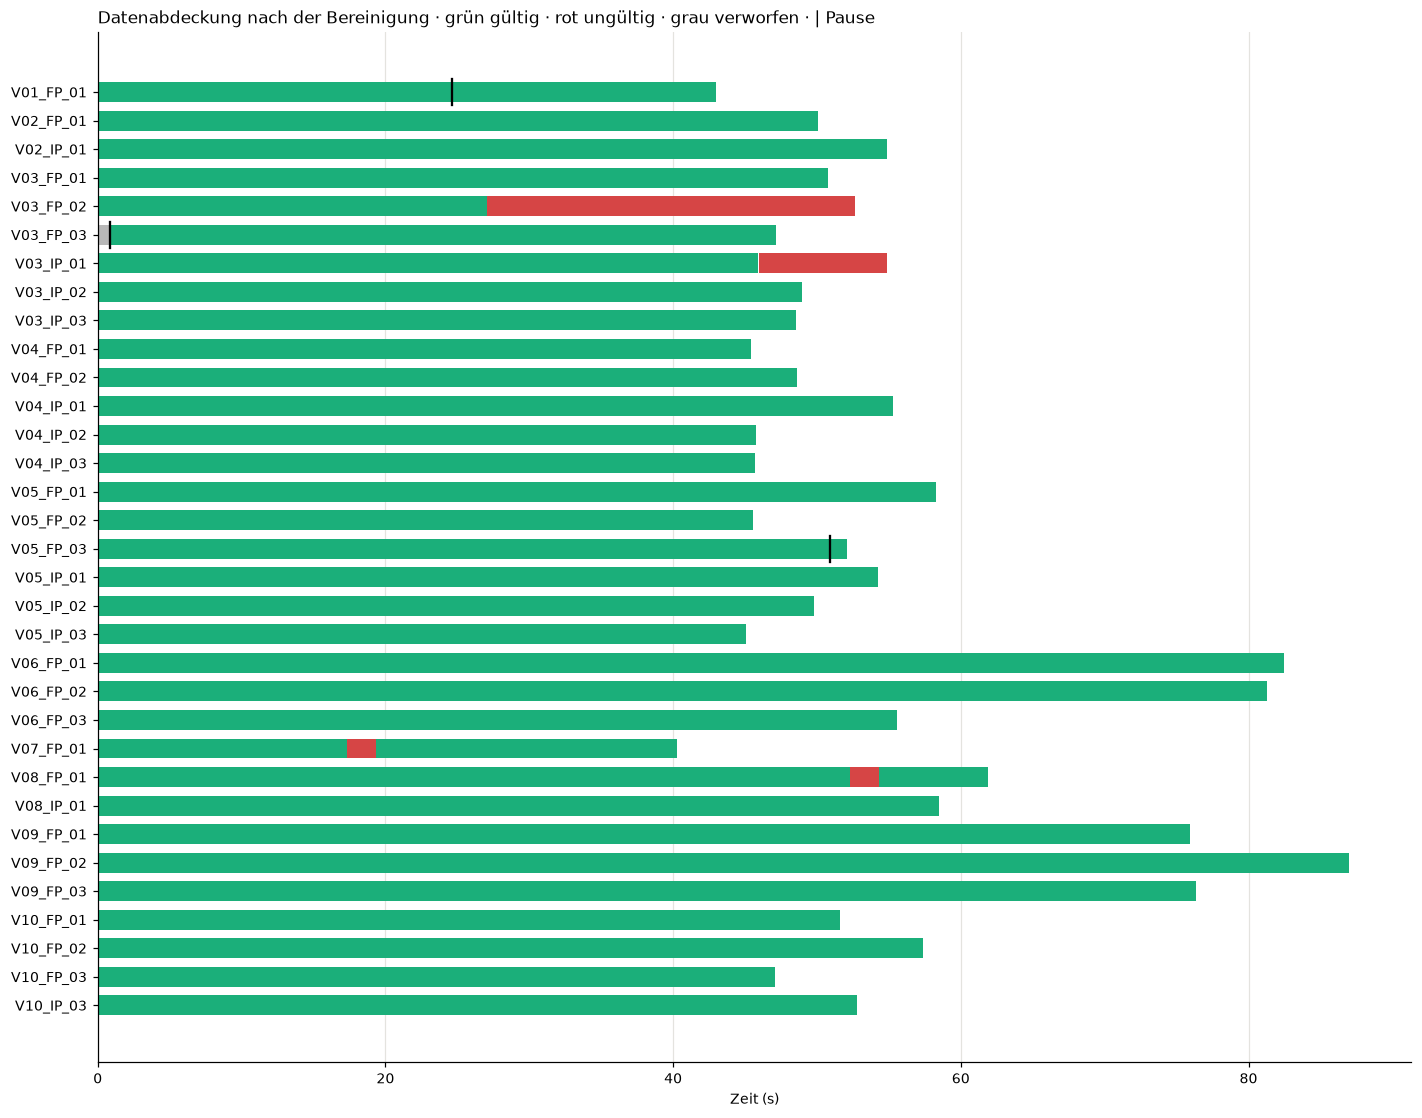

In [8]:
fig, ax = plt.subplots(figsize=(13, 0.28 * len(rec) + 1))
ids = list(rec['record_id'])
for i, rid in enumerate(ids):
    d = out['acc'][out['acc']['record_id'] == rid]
    ok = d['gueltig'].values
    t = d['t'].values
    # draw runs of equal validity as bars
    edges = np.flatnonzero(np.diff(ok.astype(int))) + 1
    for a, b in zip(np.r_[0, edges], np.r_[edges, len(t)]):
        ax.barh(i, t[b - 1] - t[a], left=t[a], height=0.7, color='#1baf7a' if ok[a] else '#d64545')
    for _, s in segments[segments['record_id'] == rid].iterrows():
        if not s['verwendet']:
            ax.barh(i, s['Länge (s)'], left=s['von (s)'], height=0.7, color='#b8b8b8')
        if s['segment'] > 0:
            ax.plot([s['von (s)']] * 2, [i - 0.45, i + 0.45], color='black', lw=1.5)
ax.set_yticks(range(len(ids)), ids); ax.invert_yaxis()
ax.grid(axis='y', visible=False); ax.set_axisbelow(True)
ax.set_xlabel('Zeit (s)')
ax.set_title('Datenabdeckung nach der Bereinigung · grün gültig · rot ungültig · grau verworfen · | Pause', loc='left')
fig.tight_layout(); fig.savefig(FIG / '01_B1_abdeckung.png', dpi=150)

## Datenregeln

| Befund | Entscheidung | Beleg |
|---|---|---|
| 5 doppelte Ordner (4× V03 iPhone, `Versuch04_Fairphone_03`) | **Aus den Rohdaten gelöscht.** Alle 9 Dateien byte-identisch zum Original geprüft. Wiederherstellbar mit `git restore` | MD5 aller Dateien |
| `Versuch04_Fairphone_03` war laut Metadaten ein iPhone | Mit den Duplikaten gelöscht; die dritte Fairphone-Messung in V04 fehlt | `meta/device.csv` |
| V03 liegt in zwei Ordnern | Gemeinsame ID `V03_…`, Ordner bleiben in den Rohdaten unverändert | Abschnitt 1 |
| Keine NaN, keine rückwärts laufenden oder doppelten Zeitstempel in Beschleunigung und Magnetfeld | Keine Imputation nötig | Abschnitt 2 |
| Aufnahmepausen in 3 Messungen; Zeitstempel laufen ohne Lücke weiter | An den START-Ereignissen in Segmente teilen; Segmente unter 1 s verwerfen | `meta/time.csv`, Abschnitt 3 |
| Rucke über 15 m/s² | ±1 s als ungültig markieren | Abschnitt 4 |
| Handy nach einem Ruck dauerhaft verschoben (Δ\|B\| > 10 µT) | Ab 1 s vor dem Ruck bis zum Ende ungültig | Abschnitt 4 |
| Ortsfeste iPhones, V01 Vorversuch, V07 ohne Fahrt | Gültig, aber mit Hinweis; Auswahl in der Fensterbildung | Abschnitt 5 |
| Unterschiedliche Abtastraten (Fairphone 427 / 100 Hz, iPhone 100 Hz) | Nicht hier angleichen; erst bei der Fensterbildung entscheiden | Abschnitt 2 |
| Andere Sensoren (Gyroskop, GPS mit NaN, Barometer, …) | Für diesen Test nicht verwendet, in den Rohdaten belassen | – |

## Befund

- **33 Messungen** (21 Fairphone, 12 iPhone), keine Duplikate mehr. Die 5 doppelten Ordner wurden aus den Rohdaten gelöscht.
- **Beschleunigung und Magnetfeld sind sauber:** keine NaN, keine rückwärts laufenden oder doppelten Zeitstempel. Abtastraten konstant: Fairphone 427 Hz (Beschleunigung) / 100 Hz (Magnetfeld), iPhone 100 / 100 Hz.
- **Pausen:** 3 Messungen wurden kurz pausiert (V01_FP_01, V03_FP_03, V05_FP_03) und sind jetzt in Segmente geteilt. In V03_FP_03 wurden die ersten 0,87 s verworfen (Segment vor der Pause).
- **Ungültige Abschnitte (Abb. B1):**
  - **V03_FP_02** ab 27 s und **V03_IP_01** ab 46 s: Handy nach einem Ruck verschoben, Rest der Messung ungültig (49 % bzw. 16 % der Messung).
  - **V07_FP_01** bei 17–19 s und **V08_FP_01** bei 52–54 s: kurze Handhabung.
- **Ergebnis:** 97 % aller Messwerte sind gültig. Die bereinigten Daten liegen in `clean/` (`acc.csv`, `mag.csv`, `aufnahmen.csv`, `log.csv`) und sind die Grundlage für `02_Fenster_Features.ipynb`.
- **Für die Zustandsfrage am aussagekräftigsten** sind die Messungen mit gleichem Aufbau: Fairphone auf dem Schlitten in V06, V08, V09, V10 (Gruppe B) und iPhone auf dem Schlitten in V04, V05 (Gruppe A).